<a href="https://colab.research.google.com/github/Annette-1/SIMULACION-II/blob/main/Procesos_Derivadas_del_MB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <span style="color:magenta;"> **Procesos Derivadas del MB** </span>

<span style="color:teal;">**Nombre:** </span> Jerónimo López Annette Michelle

<span style="color:teal;"> **Objetivo:**</span> Modelar matemáticamente fenómenos aleatorios continuos que presentan fluctuaciones impredecibles pero con estructura estadística conocida.

* <span style="color:blue;">**Puente Browviano**</span>

Es el proceso

$$
X_{t}=B_t -tB_1 \quad , \quad 0 ≤t≤1
$$

Obviamente
$$X_0=0 \quad , \quad X_1=0 \quad E(X_t)= cov(X_t,X_s)$$

* <span style="color:blue;">**Movimiento Browviano deriva** </span>
$$
X_t= \mu t + σB_t \quad , \quad t \geq0
$$
 para $$\mu ϵ R \quad y \quad σ>0$$

 $$E(X_t)= cov(X_t,X_s)$$

 * <span style="color:blue;">**Movimiento Browviano Geómetrico**</span>

 $$
X_{t}=e ^{\mu t + σB_t} \quad , \quad  t \geq0
$$

In [14]:
#Importamos las librerías
import random as r
import numpy as np
import matplotlib.pyplot as plt
from math import erf, sqrt

<span style="color:purple;">**Actividad**</span>

1. Programar el Seudocódigo y graficar una trayectoria para $T=1$ y $L=10$.

2. Graficar en el mismo panel $100$ trayectorias

3. Comentarios y conclusiones.


Del código agregamos los procesos derivados del MB. Todos se construyen con funciones a partir del Movimiento Browniano estándar `brown(T,n)`.

In [15]:
def brown(T, n):
    """Trayectoria del MB estándar en [0,T] con n pasos (devuelve n+1 puntos, W_0 = 0)."""
    dt = T / n
    w_0 = 0
    lista = [w_0]
    for i in range(n):
        dw = r.gauss(0, 1)
        w_1 = w_0 + np.sqrt(dt) * dw
        lista.append(w_1)
        w_0 = w_1
    return lista

def tiempos(T, n):
    return np.linspace(0, T, n + 1)

**1.** Una trayectoria para $T=1$ y $L=10$.

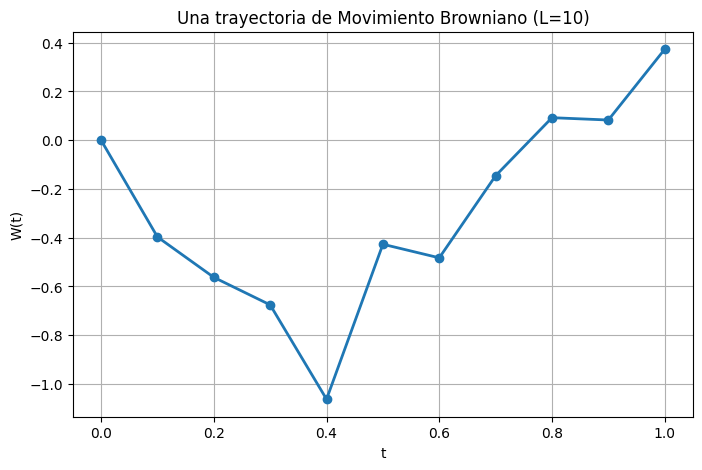

In [16]:
T, L = 1, 10
M = brown(T, L)
plt.figure(figsize=(8, 5))
plt.plot(tiempos(T, L), M, 'o-', lw=2)
plt.title("Una trayectoria de Movimiento Browniano (L=10)")
plt.xlabel("t"); plt.ylabel("W(t)"); plt.grid(True)
plt.show()

Ahora, grafiquemos en el mismo panel $100$ trayectorias simuladas junto con $f(t)=\sqrt {t}$

**Note**: Que las trayectorias inician en $0$.

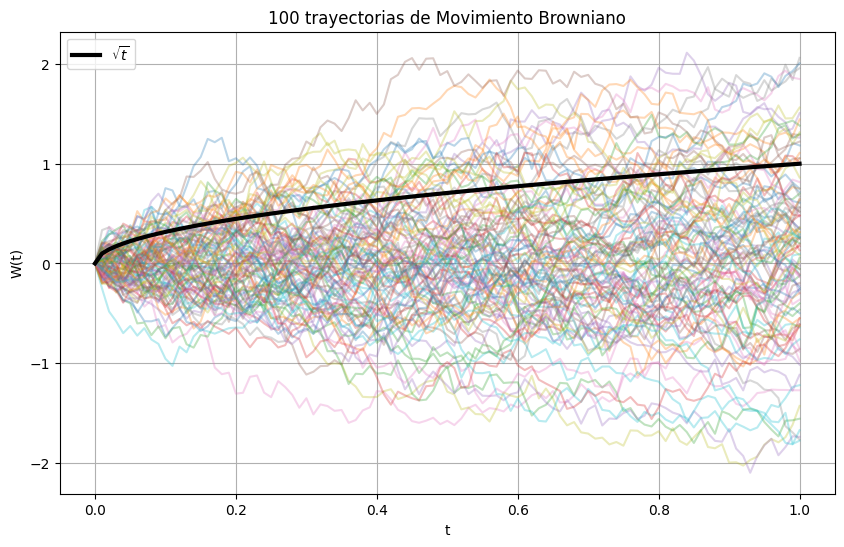

In [17]:
T, L, N = 1, 100, 100
t = tiempos(T, L)
plt.figure(figsize=(10, 6))
for k in range(N):
    plt.plot(t, brown(T, L), alpha=0.3)
plt.plot(t, np.sqrt(t), 'k', lw=3, label=r'$\sqrt{t}$')
plt.title("100 trayectorias de Movimiento Browniano")
plt.xlabel("t"); plt.ylabel("W(t)"); plt.legend(); plt.grid(True)
plt.show()

## Refinamiento de una trayectoria

Dada una trayectoria con $n$ pasos de tamaño $\Delta=T/n$, se inserta un punto en el medio de cada intervalo:

$$W_{mid}=\frac{W_{t_i}+W_{t_{i+1}}}{2}+\frac{1}{2}\sqrt{\Delta}\;Z,\qquad Z\sim N(0,1)$$

Así la trayectoria conserva sus puntos originales y pasa a tener $2n$ pasos (de tamaño $\Delta/2$).

In [18]:
def ref(lista, T):
    """Refina una trayectoria del MB en [0,T]: inserta un punto medio en cada intervalo."""
    n = len(lista) - 1            # número de pasos
    dt = np.sqrt(T / n)           # raíz del tamaño de paso actual
    nueva = []
    for i in range(n):
        dw = r.gauss(0, 1)
        w_i = 1/2 * (lista[i] + lista[i+1]) + 1/2 * dw * dt
        nueva.append(lista[i])
        nueva.append(w_i)
    nueva.append(lista[-1])
    return nueva

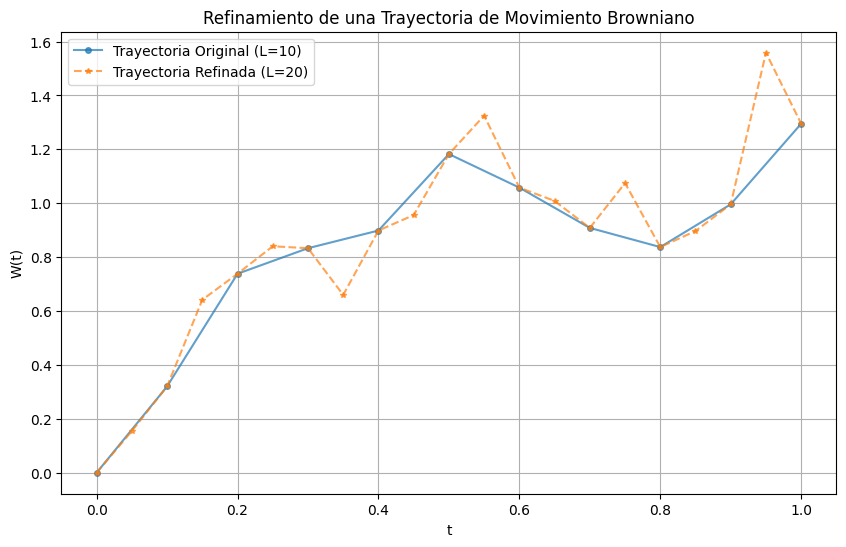

In [19]:
T = 1
L = 10
W_orig = brown(T, L)              # trayectoria original con L=10 pasos
W_ref = ref(W_orig, T)            # trayectoria refinada con 2L=20 pasos

plt.figure(figsize=(10, 6))
plt.plot(tiempos(T, L), W_orig, 'o-', ms=4, alpha=0.7, label=f"Trayectoria Original (L={L})")
plt.plot(tiempos(T, 2*L), W_ref, '*--', ms=4, alpha=0.7, label=f"Trayectoria Refinada (L={2*L})")
plt.title("Refinamiento de una Trayectoria de Movimiento Browniano")
plt.xlabel("t"); plt.ylabel("W(t)"); plt.legend(); plt.grid(True)
plt.show()

Agregamos el Puente Browviano definido como:

$$
X_{t}=B_t -tB_1 \quad , \quad 0 ≤t≤1
$$

Obviamente
$$X_0=0 \quad , \quad X_1=0 \quad E(X_t)= cov(X_t,X_s)$$

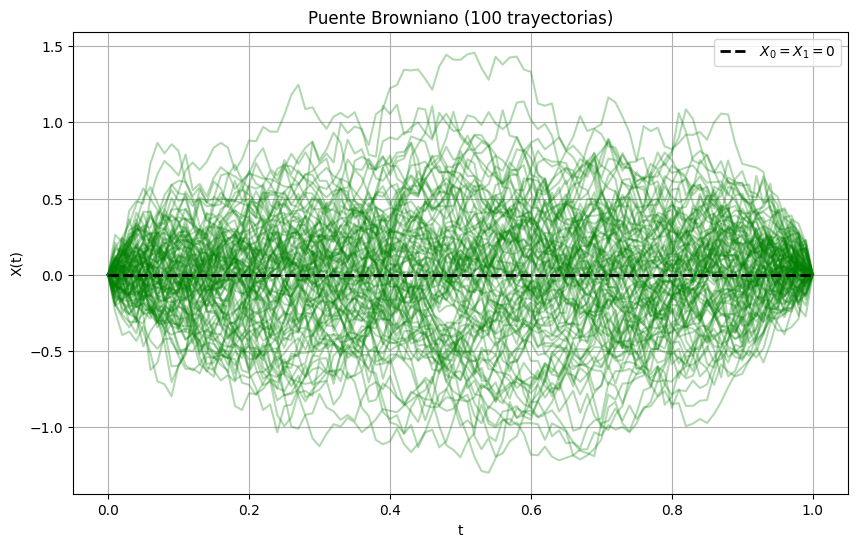

In [20]:
def puente(T, n):
    """Puente Browniano X_t = B_t - (t/T) B_T  (para T=1 es B_t - t B_1)."""
    B = np.array(brown(T, n))
    t = tiempos(T, n)
    return B - (t / T) * B[-1]

T, L, N = 1, 100, 100
t = tiempos(T, L)
plt.figure(figsize=(10, 6))
for k in range(N):
    plt.plot(t, puente(T, L), alpha=0.3, color='green')
plt.plot(t, np.zeros_like(t), 'k--', lw=2, label='$X_0 = X_1 = 0$')
plt.title("Puente Browniano (100 trayectorias)")
plt.xlabel("t"); plt.ylabel("X(t)"); plt.legend(); plt.grid(True)
plt.show()

 **Puente Browniano $X_t = B_t - t·B_1$**

* Siempre comienza en 0 y termina en 0 en $t=1$
* Se obtiene restando a cada trayectoria Browniana el valor final multiplicado por t
* Útil para simular procesos condicionados a valores iniciales y finales


Usando el movimiento Browviano Deriva:
$$
X_t= \mu t + σB_t \quad , \quad t \geq0
$$
 para $$\mu ϵ R \quad y \quad σ>0$$

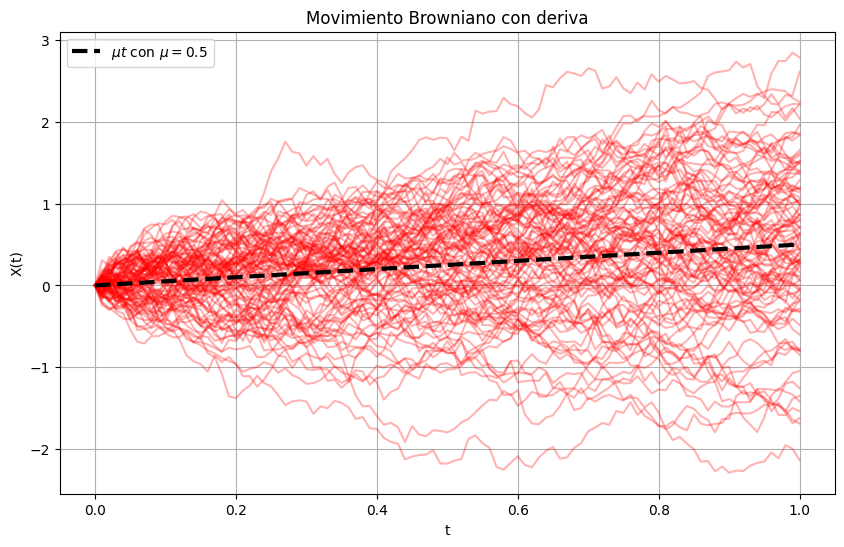

In [21]:
def deriva(mu, sigma, T, n):
    """MB con deriva X_t = mu*t + sigma*B_t."""
    B = np.array(brown(T, n))
    return mu * tiempos(T, n) + sigma * B

mu_d, sigma_d = 0.5, 1.0
T, L, N = 1, 100, 100
t = tiempos(T, L)
X_drift = np.array([deriva(mu_d, sigma_d, T, L) for _ in range(N)])

plt.figure(figsize=(10, 6))
for k in range(N):
    plt.plot(t, X_drift[k], alpha=0.3, color='red')
plt.plot(t, mu_d * t, 'k--', lw=3, label=f'$\\mu t$ con $\\mu={mu_d}$')
plt.title("Movimiento Browniano con deriva")
plt.xlabel("t"); plt.ylabel("X(t)"); plt.legend(); plt.grid(True)
plt.show()

 **Movimiento Browniano con deriva $X_t = μt + σB_t$**

* Tiene tendencia lineal $μt$ más fluctuaciones aleatorias
* Parámetros: μ (deriva) y σ (volatilidad)
* Media: $E[X_t] = μt$, Varianza: $Var[X_t] = σ²t$

Ahora aplicando movimiento Browviano Geómetrico dada por la expresión:

$$
X_{t}=e ^{\mu t + σB_t} \quad , \quad  t \geq0
$$

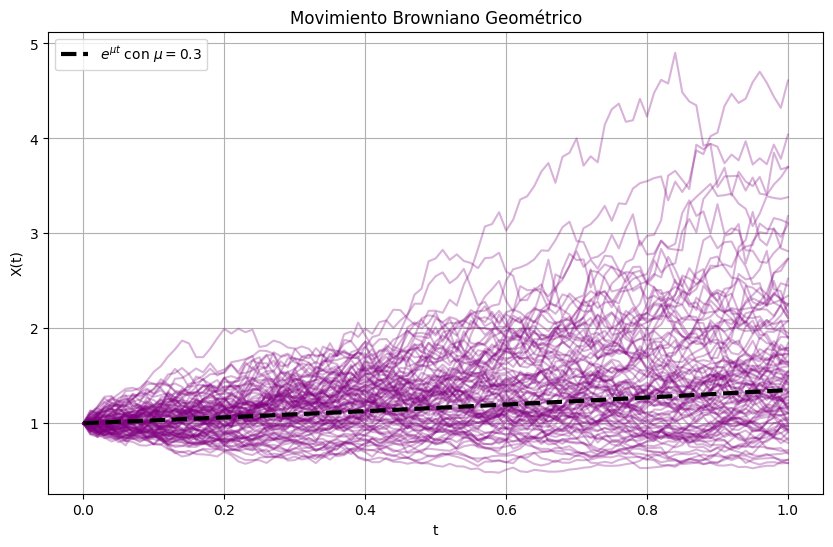

In [22]:
def geometrico(mu, sigma, T, n):
    """MB geométrico X_t = exp(mu*t + sigma*B_t)."""
    return np.exp(deriva(mu, sigma, T, n))

mu_g, sigma_g = 0.3, 0.5
X_geom = np.array([geometrico(mu_g, sigma_g, T, L) for _ in range(N)])

plt.figure(figsize=(10, 6))
for k in range(N):
    plt.plot(t, X_geom[k], alpha=0.3, color='purple')
plt.plot(t, np.exp(mu_g * t), 'k--', lw=3, label=f'$e^{{\\mu t}}$ con $\\mu={mu_g}$')
plt.title("Movimiento Browniano Geométrico")
plt.xlabel("t"); plt.ylabel("X(t)"); plt.legend(); plt.grid(True)
plt.show()

 **Movimiento Browniano Geométrico $X_t = exp(μt + σB_t)$**

* Proceso siempre positivo (exponencial de un Browniano)
* Muy usado en finanzas para modelar precios de activos
* Media: $E[X_t] = exp((μ + σ²/2)t)$
* Varianza: $Var[X_t] = e^{2μt+σ²t}\,(e^{σ²t}-1)$

In [23]:
# COMPARACIÓN DE ESPERANZAS Y VARIANZAS (teórica vs simulada, en t = T)
print("MOVIMIENTO BROWNIANO CON DERIVA:")
print(f" E[X_t]   teórica  = μt = {mu_d*T:.4f}   simulada = {np.mean(X_drift[:,-1]):.4f}")
print(f" Var[X_t] teórica  = σ²t = {sigma_d**2*T:.4f}   simulada = {np.var(X_drift[:,-1]):.4f}\n")
print("MOVIMIENTO BROWNIANO GEOMÉTRICO:")
print(f" E[X_t]   teórica  = {np.exp((mu_g + sigma_g**2/2)*T):.4f}   simulada = {np.mean(X_geom[:,-1]):.4f}")
print(f" Var[X_t] teórica  = {np.exp(2*mu_g*T + sigma_g**2*T)*(np.exp(sigma_g**2*T)-1):.4f}   simulada = {np.var(X_geom[:,-1]):.4f}")

MOVIMIENTO BROWNIANO CON DERIVA:
 E[X_t]   teórica  = μt = 0.5000   simulada = 0.5290
 Var[X_t] teórica  = σ²t = 1.0000   simulada = 0.9642

MOVIMIENTO BROWNIANO GEOMÉTRICO:
 E[X_t]   teórica  = 1.5296   simulada = 1.6173
 Var[X_t] teórica  = 0.6645   simulada = 0.6130


Analíticamente calcular la $$E(X_t)= cov(X_t,X_s)$$

**Procesos derivados del Movimiento Browniano**

* Movimiento Browniano estándar

Sea $\{W_t\}_{t\geq 0}$ un movimiento browniano estándar.

Sabemos que

$$
W_t \sim N(0,t).
$$

\subsubsection{Esperanza}

$$
E(W_t)=0.
$$

\subsubsection{Varianza}

Utilizando la definición de varianza,

$$
\operatorname{Var}(W_t)=E(W_t^2)-[E(W_t)]^2.
$$

Como $E(W_t)=0$ y $W_t\sim N(0,t)$,

$$
\operatorname{Var}(W_t)=t.
$$

Por tanto,

$$
\boxed{\operatorname{Var}(W_t)=t.}
$$

* **Covarianza**

Supongamos $s\leq t$. Entonces

$$
W_t=W_s+(W_t-W_s).
$$

Como los incrementos del movimiento browniano son independientes,

$$
\operatorname{Cov}(W_t-W_s,W_s)=0.
$$

Por tanto,
$$
\begin{align*}
\operatorname{Cov}(W_t,W_s)
&=
\operatorname{Cov}(W_s+(W_t-W_s),W_s) \\
&=
\operatorname{Var}(W_s)
+
\operatorname{Cov}(W_t-W_s,W_s) \\
&=
s.
\end{align*}
$$

Luego,

$$
\boxed{\operatorname{Cov}(W_t,W_s)=\min(t,s).}
$$

* **Puente Browniano**

Sea

$$
X_t=W_t-tW_1,
\qquad 0\leq t\leq 1.
$$

* Esperanza

$$
\begin{align*}
E(X_t)
&=
E(W_t-tW_1) \\
&=
E(W_t)-tE(W_1) \\
&=
0.
\end{align*}
$$

Por tanto,

$$
\boxed{E(X_t)=0.}
$$

* Covarianza

Sean

$$
X_t=W_t-tW_1,
\qquad
X_s=W_s-sW_1.
$$

Entonces

$$
\begin{align*}
\operatorname{Cov}(X_t,X_s)
&=
\operatorname{Cov}(W_t-tW_1,W_s-sW_1) \\
&=
\operatorname{Cov}(W_t,W_s)
-s\operatorname{Cov}(W_t,W_1) \\
&\quad
-t\operatorname{Cov}(W_1,W_s)
+ts\operatorname{Var}(W_1).
\end{align*}
$$

Usando

$$
\operatorname{Cov}(W_t,W_s)=\min(t,s),
$$

$$
\operatorname{Cov}(W_t,W_1)=t,
$$

$$
\operatorname{Cov}(W_s,W_1)=s,
$$

y

$$
\operatorname{Var}(W_1)=1,
$$

obtenemos

$$
\begin{align*}
\operatorname{Cov}(X_t,X_s)
&=
\min(t,s)-st-ts+ts \\
&=
\min(t,s)-ts.
\end{align*}
$$
Por tanto,

$$
\boxed{
\operatorname{Cov}(X_t,X_s)
=
\min(t,s)-ts.
}
$$

\subsubsection{Varianza}

Tomando $s=t$,

$$
\operatorname{Var}(X_t)
=
t-t^2.
$$

Por tanto,

$$
\boxed{
\operatorname{Var}(X_t)
=
t(1-t).
}
$$


* **Movimiento Browniano con deriva**

Sea

$$
X_t=\mu t+\sigma W_t,
\qquad \mu\in\mathbb{R},
\quad
\sigma>0.
$$

* Esperanza

$$
\begin{align*}
E(X_t)
&=
E(\mu t+\sigma W_t) \\
&=
\mu t+\sigma E(W_t) \\
&=
\mu t.
\end{align*}
$$

Luego,

$$
\boxed{
E(X_t)=\mu t.
}
$$

* Varianza

$$
\begin{align*}
\operatorname{Var}(X_t)
&=
\operatorname{Var}(\mu t+\sigma W_t) \\
&=
\sigma^2\operatorname{Var}(W_t) \\
&=
\sigma^2 t.
\end{align*}
$$

Por tanto,

$$
\boxed{
\operatorname{Var}(X_t)=\sigma^2 t.
}
$$

* Covarianza

$$
\begin{align*}
\operatorname{Cov}(X_t,X_s)
&=
\operatorname{Cov}(\mu t+\sigma W_t,\mu s+\sigma W_s) \\
&=
\sigma^2\operatorname{Cov}(W_t,W_s).
\end{align*}
$$

Luego,

$$
\boxed{
\operatorname{Cov}(X_t,X_s)
=
\sigma^2\min(t,s).
}
$$


## Ejemplo: probabilidad con MB con deriva

Encuentre la probabilidad de que el MB con parámetros $\mu=0.6$ y $\sigma^2=0.25$ tome valores entre $1$ y $3$ al tiempo $t=4$.

$$X_t=0.6\,t+0.5\,B_t \quad\Rightarrow\quad X_4=0.6(4)+0.5B_4$$

Como $B_4\sim N(0,4)$:

$$X_4\sim N\big(\mu t,\ \sigma^2 t\big)=N(2.4,\ 0.25\cdot 4)=N(2.4,\ 1)$$

$$P(1<X_4<3)=\Phi\!\left(\frac{3-2.4}{1}\right)-\Phi\!\left(\frac{1-2.4}{1}\right)=\Phi(0.6)-\Phi(-1.4)\approx 0.7257-0.0808\approx 0.6450$$

In [24]:
# Parámetros del ejemplo
mu, var = 0.6, 0.25
sigma = np.sqrt(var)          # 0.5
t_obj = 4
a, b = 1, 3

# --- Solución exacta: X_4 ~ N(mu*t, sigma^2*t) ---
def Phi(x):                    # función de distribución normal estándar
    return 0.5 * (1 + erf(x / sqrt(2)))

m, s = mu * t_obj, sigma * np.sqrt(t_obj)
p_exacta = Phi((b - m) / s) - Phi((a - m) / s)
print(f"X_4 ~ N({m}, {s**2})")
print(f"P({a} < X_4 < {b}) exacta = {p_exacta:.4f}")

X_4 ~ N(2.4, 1.0)
P(1 < X_4 < 3) exacta = 0.6450


In [25]:
# --- Simulación Monte Carlo usando deriva(mu, sigma, T, n) ---
n_sim, n_pasos = 5000, 100
X4 = np.array([deriva(mu, sigma, t_obj, n_pasos)[-1] for _ in range(n_sim)])
p_sim = np.mean((X4 > a) & (X4 < b))
print(f"P({a} < X_4 < {b}) simulada ({n_sim} trayectorias) = {p_sim:.4f}")

P(1 < X_4 < 3) simulada (5000 trayectorias) = 0.6532


In [26]:
# Gráfica con una sola trayectoria de X_t hasta t=4
tt = tiempos(t_obj, n_pasos)
X = deriva(mu, sigma, t_obj, n_pasos)

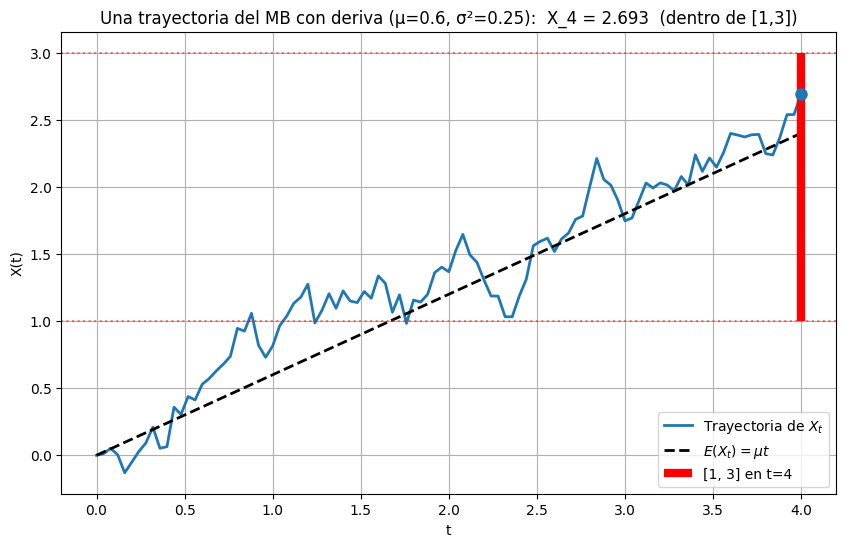

In [27]:
plt.figure(figsize=(10, 6))
plt.plot(tt, X, lw=2, label=r'Trayectoria de $X_t$')
plt.plot(tt, mu * tt, 'k--', lw=2, label=r'$E(X_t)=\mu t$')
plt.vlines(t_obj, a, b, color='red', lw=6, label=f'[{a}, {b}] en t={t_obj}')
plt.axhline(a, color='red', ls=':', alpha=0.5); plt.axhline(b, color='red', ls=':', alpha=0.5)
plt.plot(t_obj, X[-1], 'o', color='C0', ms=8)
dentro = a < X[-1] < b
plt.title(f"Una trayectoria del MB con deriva (μ={mu}, σ²={var}):  X_4 = {X[-1]:.3f}  ({'dentro' if dentro else 'fuera'} de [{a},{b}])")
plt.xlabel("t"); plt.ylabel("X(t)"); plt.legend(); plt.grid(True)
plt.show()

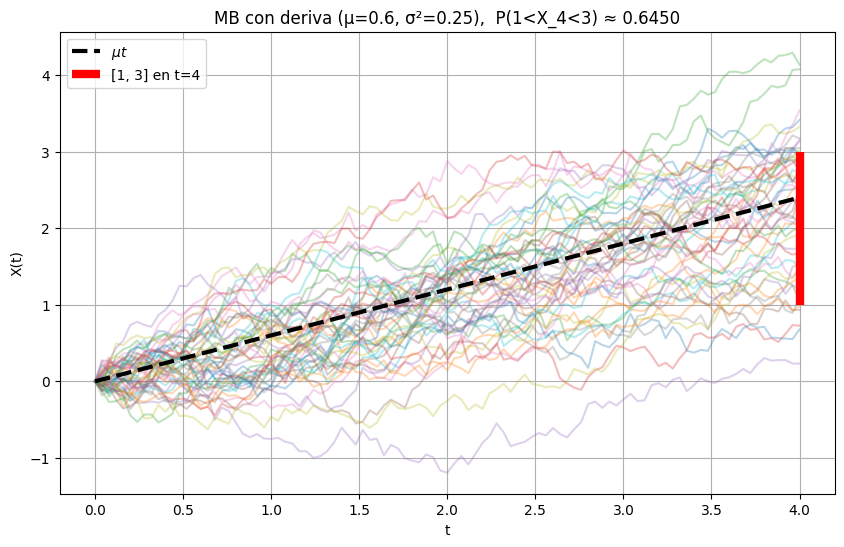

In [28]:
# Gráfica: trayectorias hasta t=4 y banda [1,3] en t=4
plt.figure(figsize=(10, 6))
tt = tiempos(t_obj, n_pasos)
for k in range(50):
    plt.plot(tt, deriva(mu, sigma, t_obj, n_pasos), alpha=0.3)
plt.plot(tt, mu * tt, 'k--', lw=3, label=r'$\mu t$')
plt.vlines(t_obj, a, b, color='red', lw=6, label=f'[{a}, {b}] en t={t_obj}')
plt.title(f"MB con deriva (μ={mu}, σ²={var}),  P({a}<X_4<{b}) ≈ {p_exacta:.4f}")
plt.xlabel("t"); plt.ylabel("X(t)"); plt.legend(); plt.grid(True)
plt.show()

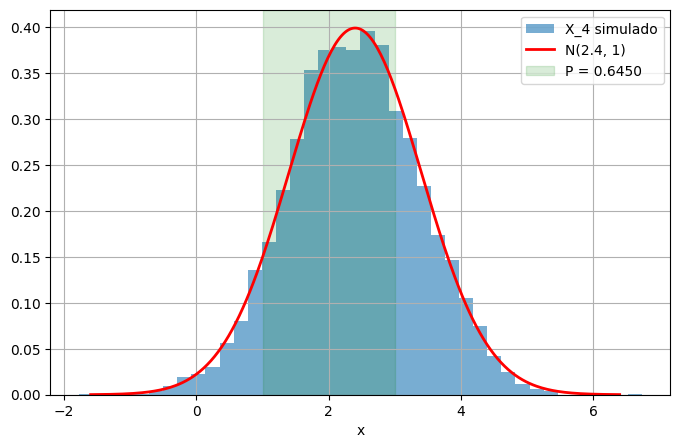

In [29]:
# Histograma de X_4 con la densidad teórica
plt.figure(figsize=(8, 5))
plt.hist(X4, bins=40, density=True, alpha=0.6, label="X_4 simulado")
x = np.linspace(m - 4*s, m + 4*s, 300)
plt.plot(x, np.exp(-(x-m)**2/(2*s**2))/(s*np.sqrt(2*np.pi)), 'r', lw=2, label="N(2.4, 1)")
plt.axvspan(a, b, color='green', alpha=0.15, label=f"P = {p_exacta:.4f}")
plt.xlabel("x"); plt.legend(); plt.grid(True)
plt.show()